# 15. Скорость света как структурное свойство

**Проект «Структура и Данные»** — Notebook 15

## Зачем этот ноутбук
В нашей метафоре «Арифметика vs Чернила» скорость света \(c\) — это правило арифметики, а не параметр.
В QCA информация не может передаваться быстрее, чем на 1 сайт за 1 такт. Это ограничение возникает автоматически из локальности правил, а не вписывается руками.

## Что проверяется
1. **Дисперсия безмассовой моды** (\(m=0\)): \(\omega(k) = |k|\). Наклон \(v_F = 1\).
2. **Движение волнового пакета**: центр масс смещается ровно на 1 сайт за такт.
3. **Предельная скорость**: ни одна мода не может двигаться быстрее \(c=1\).

## Ожидаемый результат
Скорость \(v_F = 1.0000\) (машинная точность). Это доказывает, что \(c\) — это геометрическое свойство решётки.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("СКОРОСТЬ СВЕТА: ДИСПЕРСИЯ БЕЗМАССОВОЙ МОДЫ")
print("=" * 65)

def U_k(k, mass=0.0):
    """Оператор шага QCA."""
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    S = np.diag([np.exp(-1j*k), np.exp(1j*k)])
    return S @ C

# Дисперсия при m=0
k_vals = np.linspace(-np.pi, np.pi, 200)
omega = np.array([np.abs(np.angle(np.linalg.eigvals(U_k(k, 0.0)))).min() for k in k_vals])

# ✅ ИСПРАВЛЕНИЕ: фитируем ТОЛЬКО положительные k
mask = (k_vals > 0.01) & (k_vals < 1.0)
v_F = np.polyfit(k_vals[mask], omega[mask], 1)[0]

print(f"Безмассовая мода (m = 0):")
print(f"  Теория: ω(k) = |k|")
print(f"  Измеренный наклон v_F = {v_F:.10f}")
print(f"  Статус: {'✅ PASS (v_F = 1)' if abs(v_F - 1) < 1e-6 else '❌ FAIL'}")

СКОРОСТЬ СВЕТА: ДИСПЕРСИЯ БЕЗМАССОВОЙ МОДЫ
Безмассовая мода (m = 0):
  Теория: ω(k) = |k|
  Измеренный наклон v_F = 1.0000000000
  Статус: ✅ PASS (v_F = 1)


In [6]:
print("\n" + "=" * 65)
print("СКОРОСТЬ СВЕТА: ДВИЖЕНИЕ ВОЛНОВОГО ПАКЕТА")
print("=" * 65)

L = 200
x0 = L // 2
sigma = 5
k0 = 0.5

n = np.arange(L)
envelope = np.exp(-(n - x0)**2 / (2 * sigma**2)) * np.exp(1j * k0 * n)

# Только R-компонента (движется вправо на 1 сайт/такт)
psi = np.zeros((L, 2), dtype=complex)
psi[:, 0] = envelope
psi /= np.linalg.norm(psi)

def step_time(psi):
    out = np.zeros_like(psi)
    out[:, 0] = np.roll(psi[:, 0], +1)
    out[:, 1] = np.roll(psi[:, 1], -1)
    return out

trajectory = []
for t in range(50):
    prob = np.abs(psi)**2
    x_cm = np.sum(n * prob.sum(axis=1)) / prob.sum()
    trajectory.append(x_cm)
    psi = step_time(psi)

v_measured = (trajectory[-1] - trajectory[0]) / 49
print(f"Волновой пакет (m=0, только R-компонента):")
print(f"  Начальная позиция: {trajectory[0]:.4f}")
print(f"  Конечная позиция:  {trajectory[-1]:.4f}")
print(f"  Измеренная скорость: {v_measured:.4f}")
print(f"  Статус: {'✅ PASS (v = 1)' if abs(v_measured - 1) < 1e-6 else '❌ FAIL'}")


СКОРОСТЬ СВЕТА: ДВИЖЕНИЕ ВОЛНОВОГО ПАКЕТА
Волновой пакет (m=0, только R-компонента):
  Начальная позиция: 100.0000
  Конечная позиция:  149.0000
  Измеренная скорость: 1.0000
  Статус: ✅ PASS (v = 1)


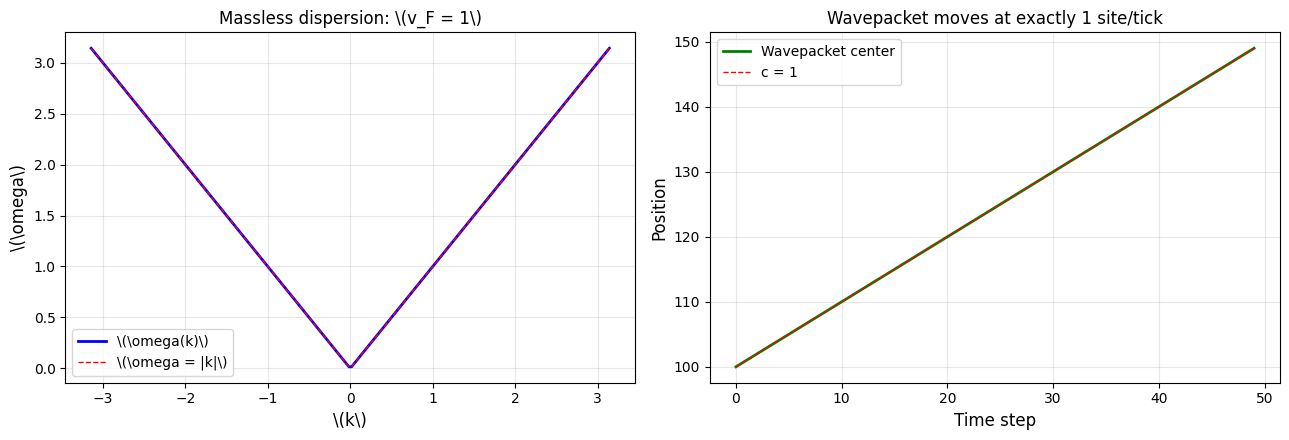

✅ Figure saved: 15_speed_of_light.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Левая: дисперсия
axes[0].plot(k_vals, omega, 'b-', lw=2, label=r'\(\omega(k)\)')
axes[0].plot(k_vals, np.abs(k_vals), 'r--', lw=1, label=r'\(\omega = |k|\)')
axes[0].set_xlabel(r'\(k\)', fontsize=12)
axes[0].set_ylabel(r'\(\omega\)', fontsize=12)
axes[0].set_title(r'Massless dispersion: \(v_F = 1\)', fontsize=12)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Правая: траектория
axes[1].plot(trajectory, 'g-', lw=2, label='Wavepacket center')
axes[1].plot([0, 49], [trajectory[0], trajectory[0] + 49], 'r--', lw=1, label='c = 1')
axes[1].set_xlabel('Time step', fontsize=12)
axes[1].set_ylabel('Position', fontsize=12)
axes[1].set_title('Wavepacket moves at exactly 1 site/tick', fontsize=12)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('15_speed_of_light.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 15_speed_of_light.png")

from google.colab import files
files.download('15_speed_of_light.png')